# Loading Data

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import warnings

warnings.filterwarnings('ignore')
plt.rcParams['figure.figsize'] = (12, 6)
sns.set_style('darkgrid')

In [2]:
df = pd.read_csv("districts.csv")

In [3]:
df

,district_id,district_name,district_type,area_km2,population,commercial_activity_index,industrial_activity_index,green_space_percent,road_capacity_index,public_transport_access_index,base_electricity_demand_mwh,temp_offset_c,wind_multiplier,population_density,grid_capacity_mwh
0,D01,Downtown,Commercial,5.2,120000,95,10,5,80,95,400,1.5,0.7,23076.923077,617.454012
1,D02,Financial District,Commercial,3.8,45000,100,5,8,85,90,500,1.2,0.6,11842.105263,843.839288
2,D03,Industrial Zone,Industrial,15.0,15000,30,100,2,70,40,800,2.0,0.9,1000.000000,1306.398788
3,D04,North Residential,Residential,12.5,180000,40,5,30,60,75,250,-0.5,1.1,14400.000000,399.916155
4,D05,South Residential,Residential,14.0,160000,35,10,25,65,70,230,0.0,1.0,11428.571429,342.471072
5,D06,East Residential,Residential,10.0,140000,25,15,20,55,60,200,0.2,1.0,14000.000000,297.799726
6,D07,West Residential,Residential,11.5,150000,45,5,28,60,65,210,-0.2,1.1,13043.478261,307.549390
7,D08,Tech Park,Commercial,6.0,25000,85,20,15,90,85,450,0.8,0.8,4166.666667,749.944816
8,D09,University District,Mixed,7.5,85000,60,0,35,50,80,180,-0.3,1.0,11333.333333,288.050176
9,D10,Airport District,Transport,25.0,5000,70,60,10,100,90,600,1.0,1.4,200.000000,976.210887


# Exploring Data

## Exploring columns and validating

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 20 entries, 0 to 19
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   district_id                    20 non-null     str    
 1   district_name                  20 non-null     str    
 2   district_type                  20 non-null     str    
 3   area_km2                       20 non-null     float64
 4   population                     20 non-null     int64  
 5   commercial_activity_index      20 non-null     int64  
 6   industrial_activity_index      20 non-null     int64  
 7   green_space_percent            20 non-null     int64  
 8   road_capacity_index            20 non-null     int64  
 9   public_transport_access_index  20 non-null     int64  
 10  base_electricity_demand_mwh    20 non-null     int64  
 11  temp_offset_c                  20 non-null     float64
 12  wind_multiplier                20 non-null     float64
 13  pop

### Converting every column to its true type

In [5]:
float_cols = ['commercial_activity_index', 'industrial_activity_index',
              'green_space_percent', 'road_capacity_index',
              'public_transport_access_index', 'base_electricity_demand_mwh']

for col in float_cols:
    df[col] = df[col].astype('float64')

### Checking for duplicated primary key (and dropping duplicates if existed)

In [6]:
# Checking for duplicated primary key
df['district_id'].duplicated().sum()

np.int64(0)

### Understanding columns + feature engineering (if needed)

In [7]:
df['district_type'].unique()

<ArrowStringArray>
[     'Commercial',      'Industrial',     'Residential',           'Mixed',
       'Transport',      'Recreation', 'Public Services']
Length: 7, dtype: str

In [8]:
df.describe()

,area_km2,population,commercial_activity_index,industrial_activity_index,green_space_percent,road_capacity_index,public_transport_access_index,base_electricity_demand_mwh,temp_offset_c,wind_multiplier,population_density,grid_capacity_mwh
count,20.0000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000,20.000000
mean,9.8250,67300.000000,56.000000,19.750000,24.500000,66.500000,70.000000,329.000000,0.240000,0.995000,8267.382641,522.124402
std,6.2476,58560.899475,26.881808,29.579287,21.139885,17.851729,18.353259,199.417573,0.916745,0.258488,6383.611536,336.607098
min,3.0000,1000.000000,15.000000,0.000000,2.000000,30.000000,30.000000,50.000000,-1.500000,0.500000,117.647059,82.905533
25%,5.1500,15000.000000,33.750000,5.000000,10.000000,55.000000,60.000000,187.500000,-0.500000,0.875000,2576.923077,289.012582
50%,8.0000,52500.000000,57.500000,10.000000,20.000000,67.500000,75.000000,240.000000,0.200000,1.000000,8333.333333,371.193614
75%,12.8750,112500.000000,77.500000,16.250000,30.000000,80.000000,85.000000,412.500000,1.000000,1.125000,13191.699605,650.576713
max,25.0000,180000.000000,100.000000,100.000000,90.000000,100.000000,95.000000,800.000000,2.000000,1.500000,23076.923077,1306.398788


In [9]:
df[~np.isclose(df['population_density'], df['population'] / df['area_km2'])]

,district_id,district_name,district_type,area_km2,population,commercial_activity_index,industrial_activity_index,green_space_percent,road_capacity_index,public_transport_access_index,base_electricity_demand_mwh,temp_offset_c,wind_multiplier,population_density,grid_capacity_mwh


In [10]:
df[(df['temp_offset_c'] > -0.1) & (df['temp_offset_c'] < 0.1)]
# D05 (South Residential) is the base to measure temp offset

,district_id,district_name,district_type,area_km2,population,commercial_activity_index,industrial_activity_index,green_space_percent,road_capacity_index,public_transport_access_index,base_electricity_demand_mwh,temp_offset_c,wind_multiplier,population_density,grid_capacity_mwh
4,D05,South Residential,Residential,14.0,160000,35.0,10.0,25.0,65.0,70.0,230.0,0.0,1.0,11428.571429,342.471072


## Checking nulls

In [11]:
df.isnull().sum()

district_id                      0
district_name                    0
district_type                    0
area_km2                         0
population                       0
commercial_activity_index        0
industrial_activity_index        0
green_space_percent              0
road_capacity_index              0
public_transport_access_index    0
base_electricity_demand_mwh      0
temp_offset_c                    0
wind_multiplier                  0
population_density               0
grid_capacity_mwh                0
dtype: int64

## Checking outliers

In [12]:
def find_outliers_iqr(df, column):
    Q1, Q3 = df[column].quantile(0.25), df[column].quantile(0.75)
    IQR = Q3 - Q1
    lower, upper = Q1 - 1.5*IQR, Q3 + 1.5*IQR
    return df[(df[column] < lower) | (df[column] > upper)]

for col in ['area_km2', 'population', 'commercial_activity_index', 'industrial_activity_index',
            'green_space_percent', 'road_capacity_index', 'public_transport_access_index',
            'base_electricity_demand_mwh', 'temp_offset_c', 'wind_multiplier', 'population_density', 'grid_capacity_mwh']:
    print(f'{col}: {len(find_outliers_iqr(df, col))}, mean: {df[col].mean():.2f}, above upper = {len(find_outliers_iqr(df, col)[df[col] > df[col].mean()])}, below lower = {len(find_outliers_iqr(df, col)[df[col] < df[col].mean()])}')

area_km2: 1, mean: 9.82, above upper = 1, below lower = 0
population: 0, mean: 67300.00, above upper = 0, below lower = 0
commercial_activity_index: 0, mean: 56.00, above upper = 0, below lower = 0
industrial_activity_index: 3, mean: 19.75, above upper = 3, below lower = 0
green_space_percent: 1, mean: 24.50, above upper = 1, below lower = 0
road_capacity_index: 0, mean: 66.50, above upper = 0, below lower = 0
public_transport_access_index: 0, mean: 70.00, above upper = 0, below lower = 0
base_electricity_demand_mwh: 1, mean: 329.00, above upper = 1, below lower = 0
temp_offset_c: 0, mean: 0.24, above upper = 0, below lower = 0
wind_multiplier: 0, mean: 0.99, above upper = 0, below lower = 0
population_density: 0, mean: 8267.38, above upper = 0, below lower = 0
grid_capacity_mwh: 1, mean: 522.12, above upper = 1, below lower = 0


## Validating Outliers

### Area

In [13]:
find_outliers_iqr(df, 'area_km2')
# It's normal not outlier since the airport should have largest area

,district_id,district_name,district_type,area_km2,population,commercial_activity_index,industrial_activity_index,green_space_percent,road_capacity_index,public_transport_access_index,base_electricity_demand_mwh,temp_offset_c,wind_multiplier,population_density,grid_capacity_mwh
9,D10,Airport District,Transport,25.0,5000,70.0,60.0,10.0,100.0,90.0,600.0,1.0,1.4,200.0,976.210887


### Industrial Activity

In [14]:
find_outliers_iqr(df, 'industrial_activity_index')
# They are normal since they are all industrial zones and an airport

,district_id,district_name,district_type,area_km2,population,commercial_activity_index,industrial_activity_index,green_space_percent,road_capacity_index,public_transport_access_index,base_electricity_demand_mwh,temp_offset_c,wind_multiplier,population_density,grid_capacity_mwh
2,D03,Industrial Zone,Industrial,15.0,15000,30.0,100.0,2.0,70.0,40.0,800.0,2.0,0.9,1000.000000,1306.398788
9,D10,Airport District,Transport,25.0,5000,70.0,60.0,10.0,100.0,90.0,600.0,1.0,1.4,200.000000,976.210887
11,D12,Harbor District,Industrial,18.0,12000,50.0,95.0,5.0,75.0,50.0,700.0,-0.5,1.5,666.666667,1184.734224


### Green space

In [15]:
find_outliers_iqr(df, 'green_space_percent')
# Normal since it's a park

,district_id,district_name,district_type,area_km2,population,commercial_activity_index,industrial_activity_index,green_space_percent,road_capacity_index,public_transport_access_index,base_electricity_demand_mwh,temp_offset_c,wind_multiplier,population_density,grid_capacity_mwh
12,D13,Central Park,Recreation,8.5,1000,20.0,0.0,90.0,40.0,60.0,50.0,-1.5,1.2,117.647059,82.905533


### Electricity Demand

In [16]:
find_outliers_iqr(df, 'base_electricity_demand_mwh')
# Normal since it's industrial zone will use alot of electricity

,district_id,district_name,district_type,area_km2,population,commercial_activity_index,industrial_activity_index,green_space_percent,road_capacity_index,public_transport_access_index,base_electricity_demand_mwh,temp_offset_c,wind_multiplier,population_density,grid_capacity_mwh
2,D03,Industrial Zone,Industrial,15.0,15000,30.0,100.0,2.0,70.0,40.0,800.0,2.0,0.9,1000.0,1306.398788


### Grid capacity

In [17]:
find_outliers_iqr(df, 'grid_capacity_mwh')
# Normal since it's industrial zone will use alot of electricity

,district_id,district_name,district_type,area_km2,population,commercial_activity_index,industrial_activity_index,green_space_percent,road_capacity_index,public_transport_access_index,base_electricity_demand_mwh,temp_offset_c,wind_multiplier,population_density,grid_capacity_mwh
2,D03,Industrial Zone,Industrial,15.0,15000,30.0,100.0,2.0,70.0,40.0,800.0,2.0,0.9,1000.0,1306.398788


# Important KPIs

## Area per district

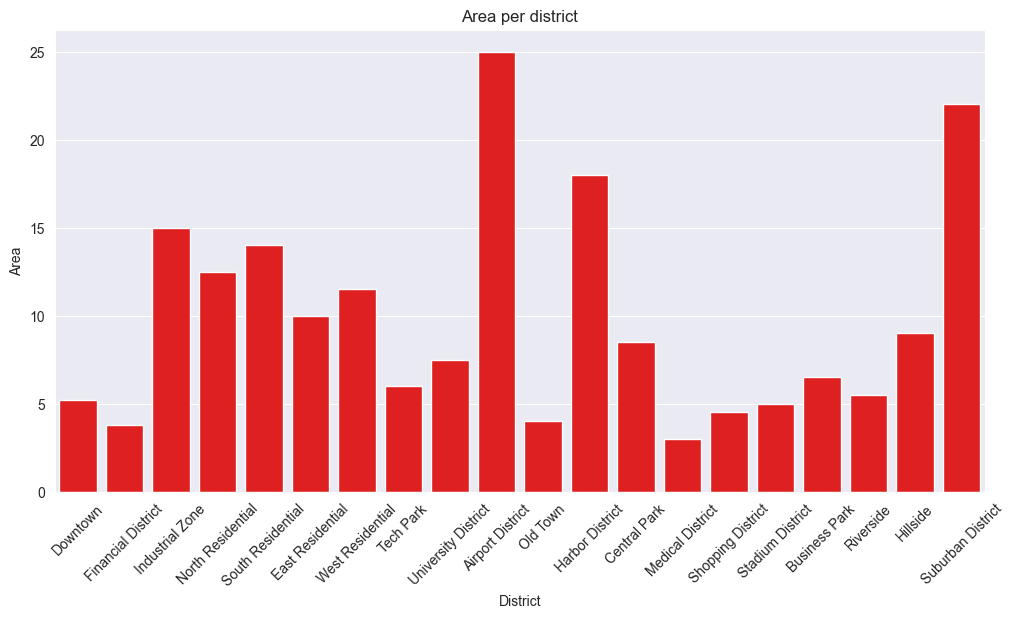

In [18]:
sns.barplot(df, x='district_name', y='area_km2', color='red')
plt.xticks(rotation=45)
plt.xlabel('District')
plt.ylabel('Area')
plt.title('Area per district')

plt.show()

## Population per district

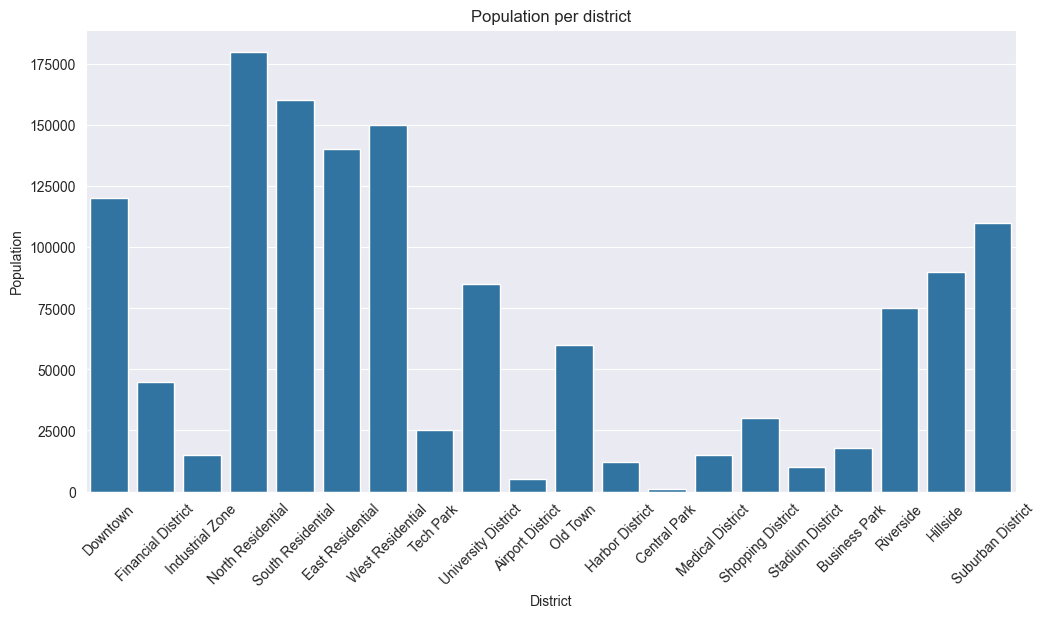

In [19]:
sns.barplot(df, x='district_name', y='population')
plt.xticks(rotation=45)
plt.xlabel('District')
plt.ylabel('Population')
plt.title('Population per district')

plt.show()

## population density per district

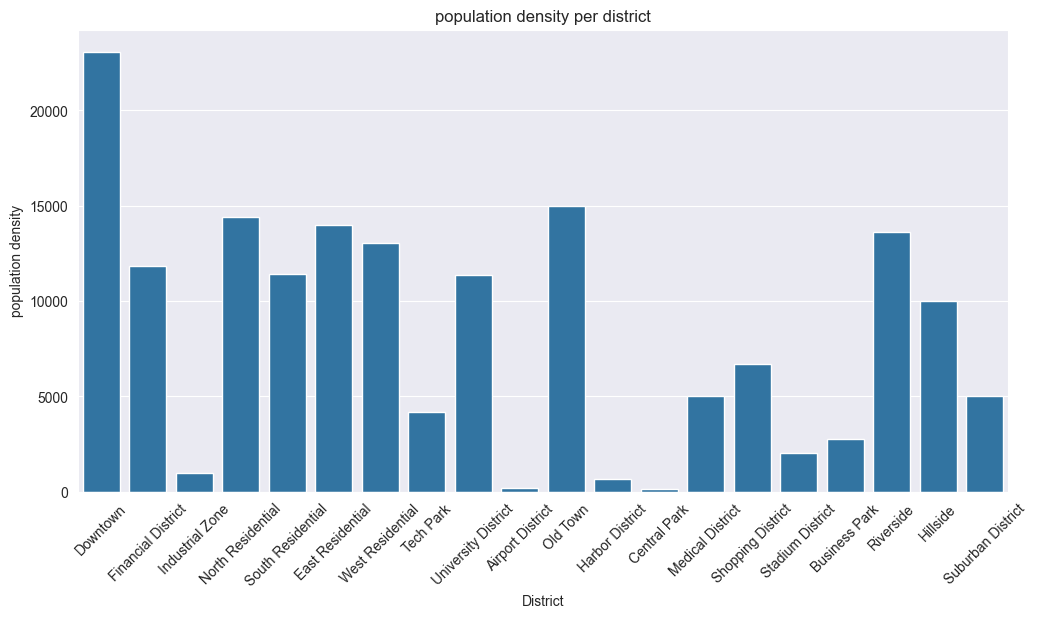

In [20]:
sns.barplot(df, x='district_name', y='population_density')
plt.xticks(rotation=45)
plt.xlabel('District')
plt.ylabel('population density')
plt.title('population density per district')

plt.show()

## green space percentage per district

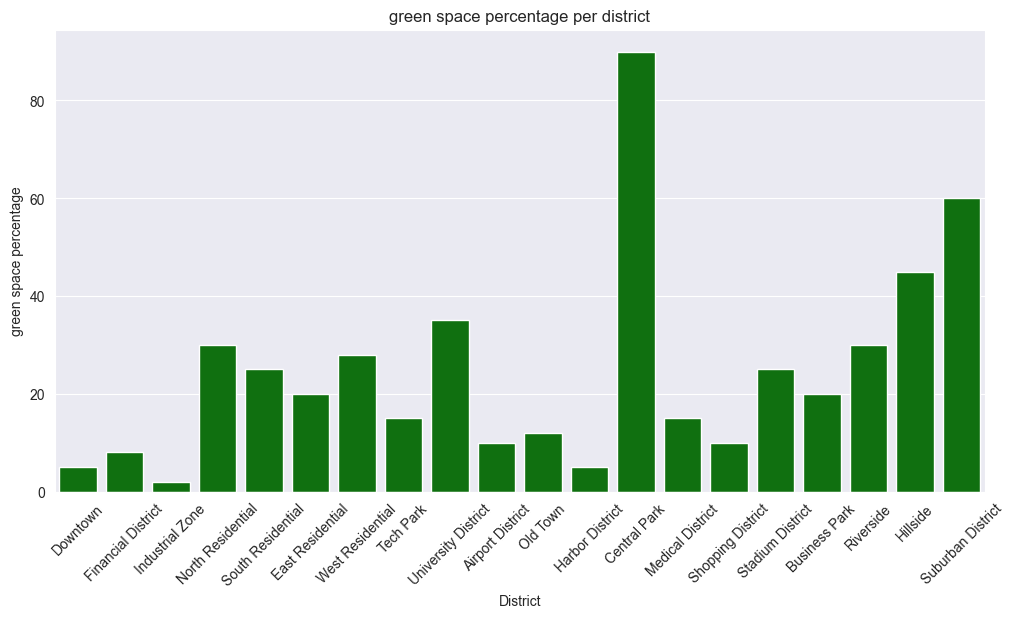

In [21]:
sns.barplot(df, x='district_name', y='green_space_percent', color='green')
plt.xticks(rotation=45)
plt.xlabel('District')
plt.ylabel('green space percentage')
plt.title('green space percentage per district')

plt.show()

## Activities per District

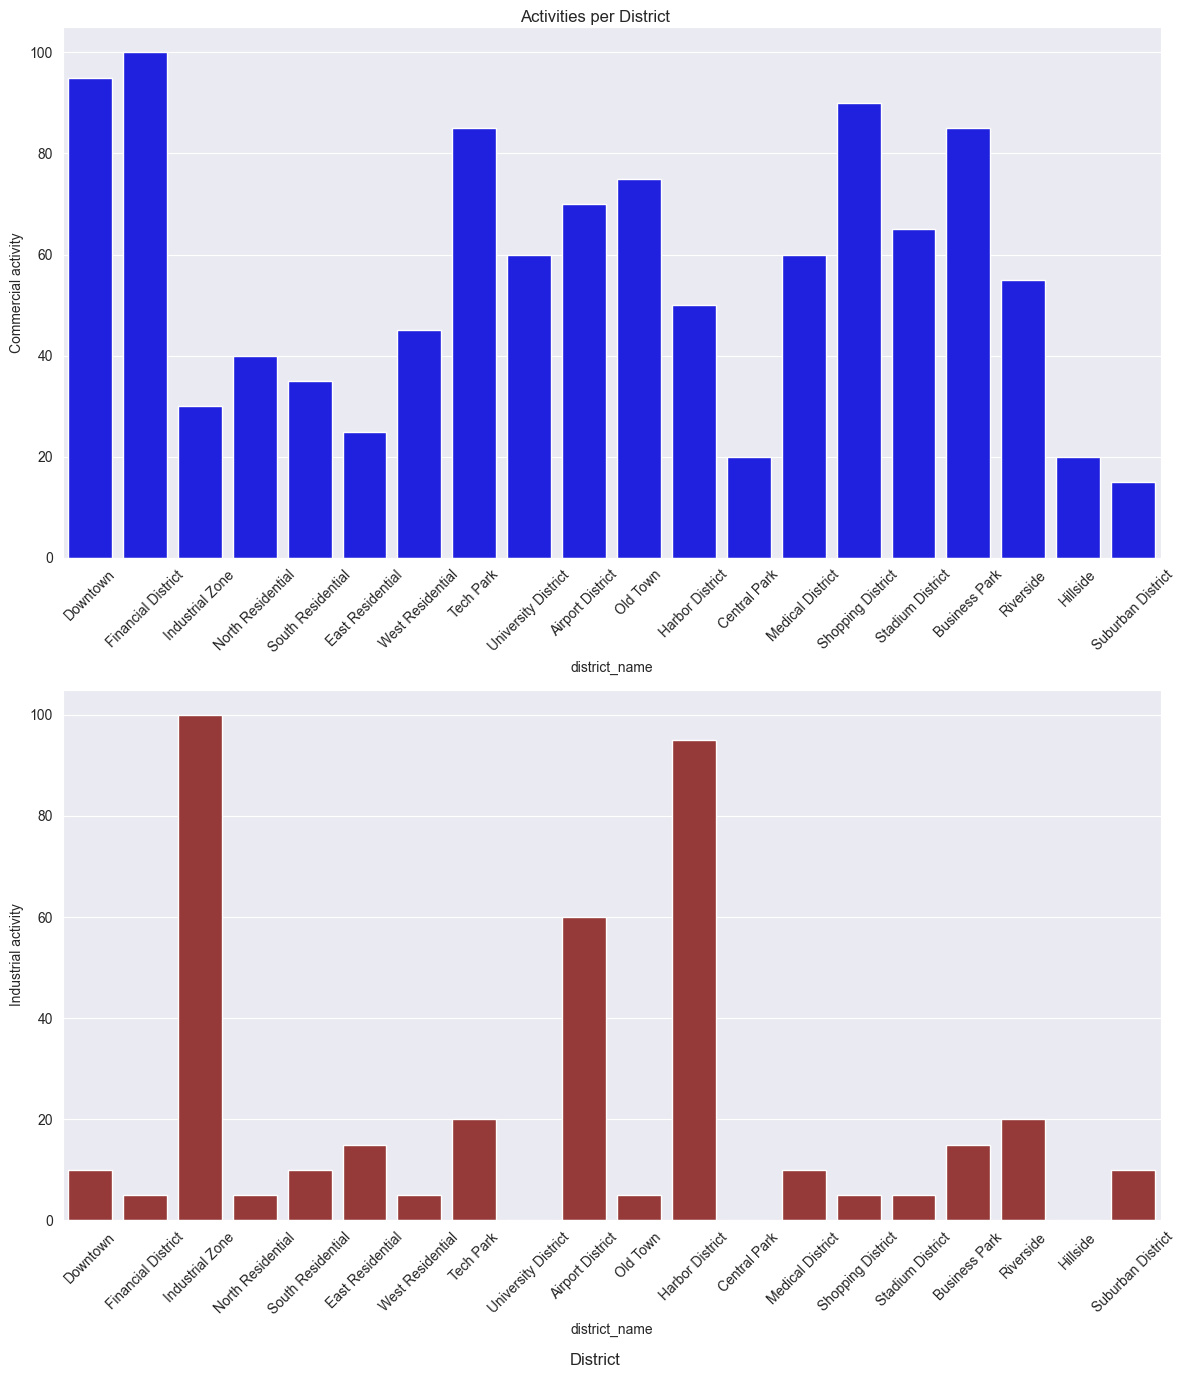

In [22]:
fig, ax = plt.subplots(2, 1, figsize=(12,14))

fig.supxlabel('District')
fig.suptitle('Activities per District')

sns.barplot(df, x='district_name', y='commercial_activity_index', color='blue', ax=ax[0])
ax[0].tick_params(axis='x', labelrotation=45)
ax[0].set_ylabel('Commercial activity')

sns.barplot(df, x='district_name', y='industrial_activity_index', color='brown', ax=ax[1])
ax[1].tick_params(axis='x', labelrotation=45)
ax[1].set_ylabel('Industrial activity')

plt.tight_layout()
plt.show()

## Transport Accessibility per District

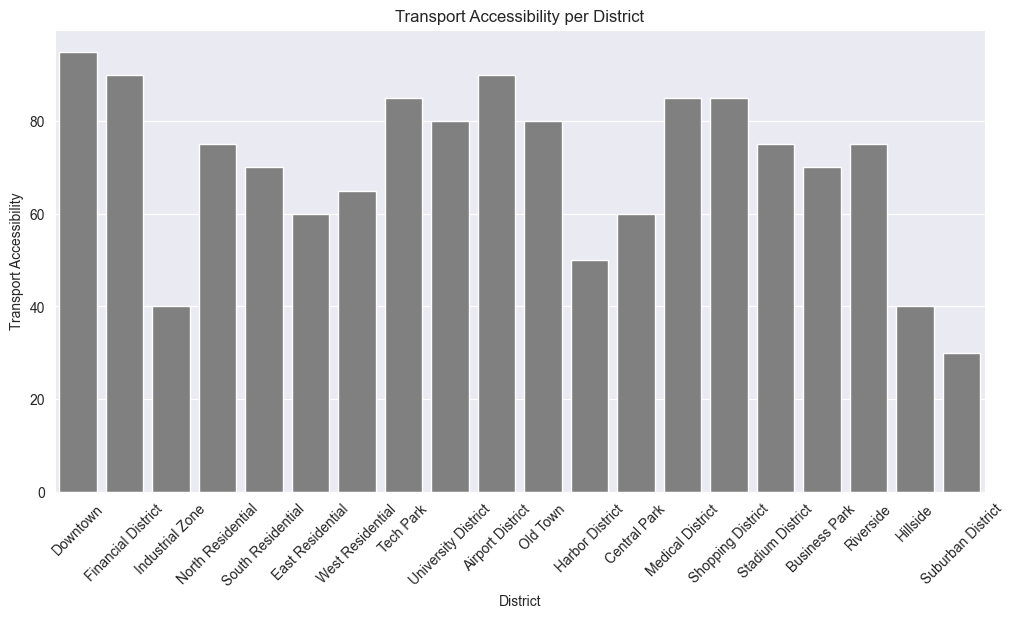

In [23]:
sns.barplot(df, x='district_name', y='public_transport_access_index', color='grey')
plt.xlabel('District')
plt.ylabel('Transport Accessibility')
plt.title('Transport Accessibility per District')
plt.xticks(rotation=45)

plt.show()